# A hop in a crystal: the barrier of a lithium ion from the field around its path

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/10_a_hop_in_a_crystal.ipynb)

The samples of the earlier notebooks are molecules, or a spectrum. Here the structure is a
**crystal**: a cell of atoms that repeats in all three directions. The property is the energy
barrier that a lithium ion has to pass when it moves from one site of the crystal to the next. A
solid conducts lithium ions well if such barriers are low along a path that runs through the
whole crystal, which is what a solid electrolyte of a battery needs.

The sample is not the whole crystal. It is one **hop**: two neighbouring lithium sites of one
crystal, with the moving ion taken out. What decides the barrier is the framework of atoms
around the path, and that is described as everything else in this program is described: by
fields. In the words of the first notebook, the framework is the receptor, the ion is the ligand
and the barrier is the binding energy.

- **The structures** are 472 compounds of lithium, oxygen and one more element from the
  Materials Project, a public database of computed crystal structures.
- **The property** is the barrier of a hop in the bond-valence model, a fast empirical model of
  the energy of an ion in an oxide. It is a computed number and not a measured one. The question
  of the notebook is therefore whether a model of fields can learn a known function of the
  structure, from one crystal to another, and what it needs for that.

The notebook follows the pattern of the earlier ones: related samples are held out together, the
model is compared with what one or two simple numbers give, and the co-field is read with its
error. One step is too slow to run here, and its stored result is read from the repository; the
text says where.

Running time: two to four minutes.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The data: crystals and their hops

The repository stores the structures and their hops in one prepared file, and the script of the
benchmark has the function that reads it. A `HopSet` holds the structures (as `Atoms` objects of
the ASE library), the hops and their labels.

Every pair of lithium sites between 1.5 and 4.5 Å apart is a hop, through the faces of the cell
too, because the crystal continues there. Most hops of a crystal are copies of each other by its
symmetry, so one of each kind is kept. At most six kinds per structure are used, so that the
large cells do not dominate.

In [2]:
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "benchmarks")
import run_hops                                    # the benchmark script; it holds the loader

hops = run_hops.load_prepared(run_hops.PREPARED, max_per_structure=6, seed=0)
sample = [i for i, h in enumerate(hops.hops) if h.representative == i and np.isfinite(h.y)]
targets = hops.targets(sample)                    # the sample, with the structure of every hop
barrier = np.asarray(targets.y, float)

print(len(hops.structures), "structures,", len(hops.hops), "hops in all")
print(len(sample), "distinct hops in the sample, from", targets.n_measured_molecules, "structures")
k = 0
cell = hops.structures[k]
kinds = {h.representative for h in hops.hops if h.structure == k}
print("the first structure: %s, %d atoms in the cell, %d hops of %d kinds"
      % (hops.names[k], len(cell), len(hops.of_structure(k)), len(kinds)))
print("barrier: %.2f to %.2f eV, mean %.2f, standard deviation %.2f" % (barrier.min(), barrier.max(), barrier.mean(), barrier.std()))

472 structures, 24004 hops in all
1732 distinct hops in the sample, from 459 structures
the first structure: mp-1002572 LiMnO2, 16 atoms in the cell, 40 hops of 20 kinds
barrier: 0.00 to 7.67 eV, mean 0.89, standard deviation 0.81


As in the ninth notebook, the structures are checked before anything is modelled: no two atoms
may be much closer than the sum of their covalent radii. In a crystal the check must count the
copies of the cell, because the nearest neighbour of an atom can be an atom of the next cell.
`get_all_distances(mic=True)` does that.

the closest pair of all, relative to the covalent radii: V-O at 1.59 A, 0.73 of the sum of the radii
structures with a pair below 0.7 of that sum: 0


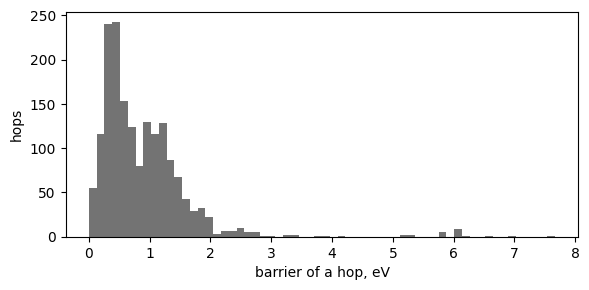

hops with a barrier above 2 eV: 72 of 1732


In [3]:
from ase.data import covalent_radii

closest = []                                      # for every structure: (ratio, distance, pair)
for atoms in hops.structures:
    distance = atoms.get_all_distances(mic=True)
    np.fill_diagonal(distance, np.inf)
    radii = covalent_radii[atoms.numbers]
    ratio = distance / (radii[:, None] + radii[None, :])
    i, j = np.unravel_index(np.argmin(ratio), ratio.shape)
    closest.append((ratio[i, j], distance[i, j], atoms.symbols[i] + "-" + atoms.symbols[j]))
ratio, distance, pair = min(closest)
print("the closest pair of all, relative to the covalent radii: %s at %.2f A, %.2f of the sum of the radii" % (pair, distance, ratio))
print("structures with a pair below 0.7 of that sum:", sum(row[0] < 0.7 for row in closest))

fig, ax = plt.subplots(figsize=(6.0, 3.0))
ax.hist(barrier, bins=60, color="0.45")
ax.set_xlabel("barrier of a hop, eV"); ax.set_ylabel("hops"); plt.tight_layout(); plt.show()
print("hops with a barrier above 2 eV: %d of %d" % (np.sum(barrier > 2.0), len(barrier)))

No structure has a pair of atoms below 0.7 of the sum of the covalent radii, which is the limit
that the ninth notebook used. The barriers have a long tail: most hops are near or below 1 eV,
and a few are several eV high. Those are pairs of sites whose straight connection runs
close to another atom. No ion takes such a path, and the label says so with a high number. The
tail matters for the scores below, because q² is computed from squared errors.

## The environment of a hop

The description of a hop is its **environment**: every atom within 6 Å of the midpoint of the
two sites, with the copies from the neighbouring cells, and without the moving ion. Each atom
enters with a weight that falls with its distance from the midpoint, so the atoms near the path
count most. The environment is then an ordinary set of atoms with fields, as a molecule is.

The fields are the ones the program uses for inorganic crystals: the electrostatic field of the
formal charges of the ions (Li⁺, O²⁻ and so on), the steric field, the electronegativity, and
one field for each of the frequent elements, which is 1 on the atoms of that element.

The plot shows one environment in the coordinates that belong to a hop: z along the hop, and r,
the distance from its axis.

fields: electrostatic, steric, prop:electronegativity, cif:Co, cif:Cr, cif:Li, cif:Mn, cif:Ni, cif:O, cif:Ti, cif:V, cif:other


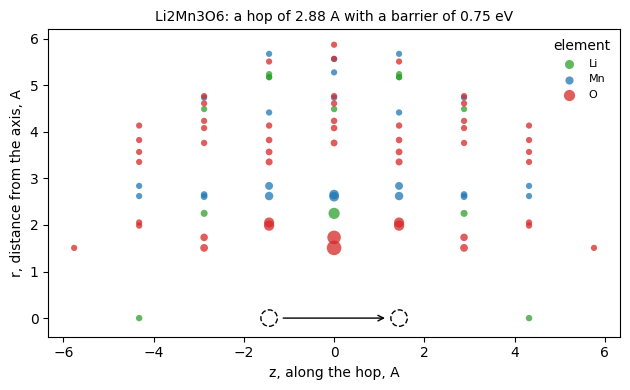

88 atoms in this environment; the larger a point, the larger its weight


In [4]:
from cmfqsar.hops import framed_environments

fieldset = run_hops.fieldset_for(hops, "file")
crystals = hops.crystals(fieldset)               # the fields of every structure
print("fields:", ", ".join(fieldset.names))

shown = next(i for i in sample if 2.8 < hops.hops[i].length < 3.2 and 0.3 < hops.hops[i].y < 0.8)
hop = hops.hops[shown]
environment = framed_environments(hops, crystals, rows=[shown], rho=0.25, r_max=6.0)[0]
xyz, symbols = environment.coords[1:], environment.symbols[1:]        # atom 0 marks the midpoint
z, r = xyz[:, 2], np.hypot(xyz[:, 0], xyz[:, 1])
weight = np.exp(-0.25 * np.sum(xyz ** 2, axis=1))

fig, ax = plt.subplots(figsize=(6.4, 4.0))
colours = {"O": "tab:red", "Li": "tab:green"}
for element in sorted(set(symbols)):
    rows = np.array([s == element for s in symbols])
    ax.scatter(z[rows], r[rows], s=20 + 160 * weight[rows], color=colours.get(element, "tab:blue"),
               alpha=0.75, lw=0, label=element)
ax.scatter([-hop.length / 2, hop.length / 2], [0, 0], s=140, facecolors="none", edgecolors="k", linestyles="--")
ax.annotate("", (hop.length / 2 - 0.25, 0), (-hop.length / 2 + 0.25, 0), arrowprops=dict(arrowstyle="->", color="k"))
ax.set_xlabel("z, along the hop, A"); ax.set_ylabel("r, distance from the axis, A"); ax.set_ylim(-0.4, 6.2)
ax.legend(frameon=False, fontsize=8, title="element")
ax.set_title("%s: a hop of %.2f A with a barrier of %.2f eV" % (hops.names[hop.structure].split()[-1], hop.length, hop.y), fontsize=10)
plt.tight_layout(); plt.show()
print(len(symbols), "atoms in this environment; the larger a point, the larger its weight")

The dashed circles are the two sites of the moving ion. The atoms nearest to the axis halfway
between them form the **bottleneck**, the narrowest place of the path.

## Which samples are held out together

The hops of one crystal are not independent of each other: they share the cell, the elements
and often the same neighbours. If some hops of a crystal are in the training set while others
are predicted, the model can recognise the crystal. So the folds hold out **whole structures**,
and `targets.folds` makes such folds. The intervals below resample structures for the same
reason.

## The references: two numbers, and counts of atoms

Before a field is used, two simpler descriptions are tried.

- **Two numbers that a chemist would start from**: the length of the hop and the free space at
  its bottleneck, which is the distance from the axis to the surface of the nearest atom. A
  linear regression on the two.
- **Counts of atoms**: how many atoms of each element lie in each of several shells around the
  midpoint. This description knows which elements are near the path and how many, and it does
  not know where they are around it. A kernel ridge regression on the counts, with the ridge
  parameter chosen on the folds.

In [5]:
from types import SimpleNamespace
from cmfqsar.hops import hop_count_features, hop_types
from cmfqsar.localenv import choose_lam, count_kernel, local_features, local_kernel, paired_interval

FOLDS, SEED = 10, 0
folds = targets.folds(FOLDS, SEED)               # each fold holds out whole structures


def q2(y, predicted):
    return 1.0 - np.sum((y - predicted) ** 2) / np.sum((y - np.mean(y)) ** 2)


def regression(columns, y, folds):
    """A linear regression on the columns, each fold predicted by a fit to the other folds."""
    X = np.column_stack([np.ones(len(y)), columns])
    predicted = np.empty(len(y))
    for held_out in folds:
        train = np.setdiff1d(np.arange(len(y)), held_out)
        predicted[held_out] = X[held_out] @ np.linalg.lstsq(X[train], y[train], rcond=None)[0]
    return predicted


results = {}
length = np.array([hops.hops[i].length for i in targets.atom])
free_space = np.array([hops.hops[i].bottleneck for i in targets.atom])
print("correlation of the barrier with the length %+.2f, with the free space at the bottleneck %+.2f"
      % (np.corrcoef(length, barrier)[0, 1], np.corrcoef(free_space, barrier)[0, 1]))
results["length and bottleneck"] = SimpleNamespace(predicted=regression(np.column_stack([length, free_space]), barrier, folds))

wide = hops.environments(crystals, rows=targets.atom, rho=0.1, r_max=6.0)       # reaches to 6 A
elements = hop_types(wide, min_atoms=20)
results["counts of atoms"] = choose_lam(count_kernel(hop_count_features(wide, elements)), targets, folds=FOLDS, seed=SEED)
print("%d environments, %.0f atoms each at the mean; counts for %d elements" % (len(wide), np.mean([e.n_atoms for e in wide]), len(elements)))
print()
for label, result in results.items():
    print("%-24s q2 %+.3f   mean absolute error %.3f eV" % (label, q2(barrier, result.predicted), np.mean(np.abs(barrier - result.predicted))))

correlation of the barrier with the length +0.23, with the free space at the bottleneck -0.34


1732 environments, 89 atoms each at the mean; counts for 60 elements

length and bottleneck    q2 +0.102   mean absolute error 0.510 eV
counts of atoms          q2 +0.491   mean absolute error 0.403 eV


The two numbers of the chemist explain a tenth of the variance. The counts explain half of it.
So half of the barrier is decided by which atoms surround the path and how many, and a field
model has to be compared with that number and not with zero.

## The fields of the environment, compared without a frame

The first field model uses no frame. The rotation-invariant kernel of the second notebook, in
its form for one environment, compares two environments by the distances between their atoms,
for every pair of fields. So it knows which atoms are near the path, as the counts do, and it
also knows how they lie relative to each other.

Its setting is the width of the weight that falls with the distance from the midpoint. The
benchmark ran three widths; the best one, 2 Å, is run here.

length and bottleneck    q2 +0.102   mean absolute error 0.510 eV
counts of atoms          q2 +0.491   mean absolute error 0.403 eV
fields, no frame         q2 +0.657   mean absolute error 0.307 eV



fields, no frame minus counts of atoms: +0.165 [+0.097, +0.266]


counts of atoms minus length and bottleneck: +0.389 [+0.216, +0.496]


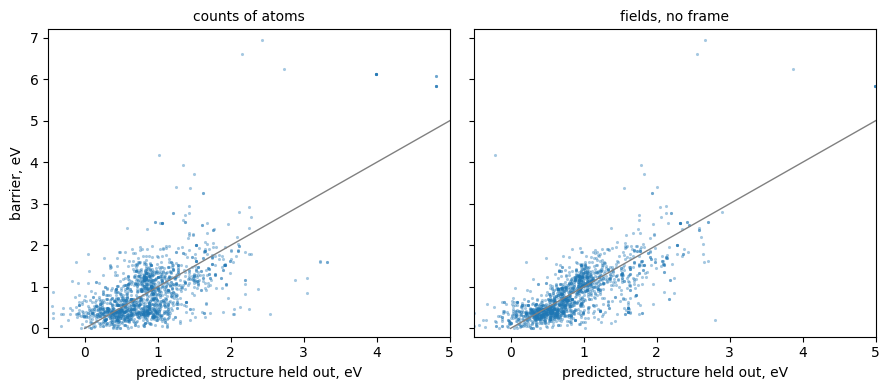

In [6]:
narrow = hops.environments(crystals, rows=targets.atom, rho=0.25, r_max=6.0)    # a width of 2 A
K = local_kernel(local_features(narrow))
results["fields, no frame"] = choose_lam(K, targets, folds=FOLDS, seed=SEED)

for label, result in results.items():
    print("%-24s q2 %+.3f   mean absolute error %.3f eV" % (label, q2(barrier, result.predicted), np.mean(np.abs(barrier - result.predicted))))
print()
for a, b in (("fields, no frame", "counts of atoms"), ("counts of atoms", "length and bottleneck")):
    print("%s minus %s: %+.3f [%+.3f, %+.3f]" % ((a, b) + paired_interval(results[a], results[b], targets, runs=1000, seed=SEED)))

fig, axes = plt.subplots(1, 2, figsize=(9.0, 4.0), sharey=True)
for ax, label in zip(axes, ("counts of atoms", "fields, no frame")):
    ax.scatter(results[label].predicted, barrier, s=5, color="tab:blue", alpha=0.4, lw=0)
    ax.plot([0, 5], [0, 5], color="0.5", lw=1)
    ax.set_xlim(-0.5, 5); ax.set_ylim(-0.2, 7.2); ax.set_xlabel("predicted, structure held out, eV"); ax.set_title(label, fontsize=10)
axes[0].set_ylabel("barrier, eV"); plt.tight_layout(); plt.show()

The fields explain two thirds of the variance of the barrier in crystals that the model has not
seen. That is 0.17 above the counts, with an interval that excludes zero. So the arrangement of
the atoms around the path holds something that their number does not, and the model finds it.
The numbers are those of the stored benchmark (`benchmarks/results/hops/table.md`), which this
cell repeats.

The high barriers of the tail are predicted too low by both descriptions. A ridge model pulls a
rare extreme value towards the mean, and these few hops carry a large part of the squared error.

The next cell shows what the folds are worth. The same kernel is validated again with folds that
hold out single hops, so that other hops of the same crystal stay in the training set.

In [7]:
from cmfqsar.model import krr_fit

ridge = results["fields, no frame"].lam


def out_of_fold(K, y, folds, ridge):
    predicted = np.empty(len(y))
    for held_out in folds:
        train = np.setdiff1d(np.arange(len(y)), held_out)
        coefficients, bias = krr_fit(K[np.ix_(train, train)], y[train], ridge)
        predicted[held_out] = K[np.ix_(held_out, train)] @ coefficients + bias
    return predicted


order = np.random.RandomState(SEED).permutation(len(barrier))
single_hops = [order[k::FOLDS] for k in range(FOLDS)]
print("whole structures held out: q2 %+.3f" % q2(barrier, out_of_fold(K, barrier, folds, ridge)))
print("single hops held out:      q2 %+.3f" % q2(barrier, out_of_fold(K, barrier, single_hops, ridge)))

whole structures held out: q2 +0.657


single hops held out:      q2 +0.767


With single hops held out the score is higher. The difference is what the model gains from
having seen other hops of the same crystal, and it says nothing about a new crystal. The number
with whole structures held out is the one to report.

## The frame of a hop

A hop has a natural frame, as the catalysts of the ninth notebook had: the origin at the
midpoint and z along the hop. One freedom is left, the rotation about the axis, and nothing in a
crystal says how to fix it. The program does not fix it. The overlap kernel is averaged over all
rotations about the axis, which has a closed form, so it costs as much as one overlap. The class
`HopModel` holds this kernel:

```python
from cmfqsar.hops import HopModel, cross_validate_hop_model, framed_environments

framed = framed_environments(hops, crystals, rows=targets.atom, rho=0.25, r_max=6.0)
model = HopModel.build(framed, fieldset, n_jobs=8)             # the kernel: ten minutes here
result = cross_validate_hop_model(model, targets, folds=10, seed=0)
model.fit(targets.y, lam=result.lam)
table, sd = model.profile(field, zs, rs, sigma=result.error)   # the co-field, see below
```

These lines are not run in this notebook, because the kernel of 1,732 environments of 90 atoms
takes about ten minutes. The benchmark has run them (`python benchmarks/run_hops.py`), and its
results are stored. The next cell reads them.

In [8]:
import json

with open("benchmarks/results/hops/public.json", encoding="utf-8") as fh:
    stored = json.load(fh)
print("stored results for %d hops of %d structures" % (stored["n_samples"], stored["n_structures"]))
print()
print("%-12s %14s %14s   %s" % ("width, A", "no frame, q2", "frame, q2", "frame minus no frame"))
for rho in (0.05, 0.1, 0.25):
    no_frame = next(m for m in stored["models"] if m.get("key") == "invariant %g" % rho)
    frame = next(m for m in stored["models"] if m.get("key") == "overlap %g" % rho)
    pair = next(p for p in stored["pairs"] if p["a"] == "overlap %g" % rho and p["b"] == "invariant %g" % rho)
    print("%-12.1f %+14.3f %+14.3f   %+.3f [%+.3f, %+.3f]" % (1 / np.sqrt(rho), no_frame["q2"], frame["q2"], pair["diff"], pair["low"], pair["high"]))
print()
print("the 'no frame' row of this notebook at a width of 2 A: %+.3f" % q2(barrier, results["fields, no frame"].predicted))
print()
print("how the frame model grows with the number of structures:")
for point in stored["learning_curve"]:
    print("   %3d structures: q2 %+.2f" % (point["structures"], point["q2"]))

stored results for 1732 hops of 472 structures

width, A       no frame, q2      frame, q2   frame minus no frame
4.5                  +0.553         +0.630   +0.076 [-0.002, +0.145]
3.2                  +0.624         +0.649   +0.024 [-0.049, +0.099]
2.0                  +0.657         +0.662   +0.005 [-0.060, +0.071]

the 'no frame' row of this notebook at a width of 2 A: +0.657

how the frame model grows with the number of structures:
    25 structures: q2 +0.08
    50 structures: q2 +0.15
   100 structures: q2 +0.44
   200 structures: q2 +0.50
   400 structures: q2 +0.66
   459 structures: q2 +0.66


**The frame adds nothing here.** At the best width the model in the frame of the hop and the
model without a frame have the same score, and the interval of the difference is centred on
zero. Only at the widest environment is the frame a little ahead, and that interval contains
zero as well.

This is the opposite of the catalyst series of the ninth notebook, where the frame added 0.1,
and the reason can be named. A catalyst has one reaction centre, and what matters is where each
group lies relative to it. The environment of a hop is cut out around the path, and the weight
that falls with the distance already says what is near the path. With a narrow weight the
distances between the atoms hold nearly all that the frame holds.

The last lines are a warning about small sets. With 100 structures the model reaches 0.44, and
with 25 it reaches nothing. A hop model needs hundreds of structures, because every third
element of these compounds brings its own chemistry.

## The co-field of a hop: a profile along the path

The model in the frame has one thing that the model without a frame cannot have: a co-field.
Because of the average about the axis it depends on two coordinates only, z along the hop and r
from its axis. So it is a map in the plane of the first plot: where along the path, and how far
from it, an atom of a given kind raises or lowers the barrier. `HopModel.profile` returns it
with a standard deviation, which follows from the errors of the out-of-fold predictions.

The stored profile of the benchmark is drawn for three fields. Inside the dashed lines the value
is more than two standard deviations from zero.

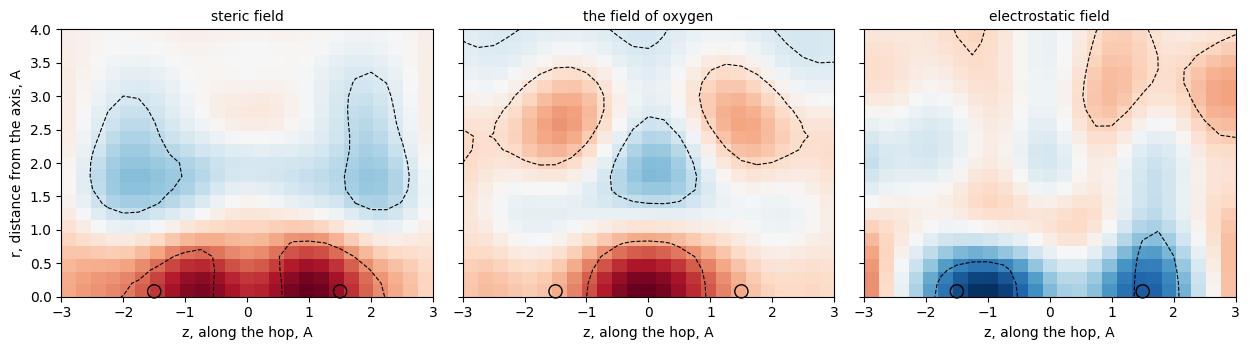

the field of oxygen at the midpoint: on the axis +3.03 (sd 1.06), 2 A from the axis -1.31 (sd 0.31)


In [9]:
with open("benchmarks/results/hops/profile_fine.json", encoding="utf-8") as fh:
    profile = json.load(fh)
zs, rs = np.array(profile["z"]), np.array(profile["r"])

fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.6), sharey=True)
for ax, (field, title) in zip(axes, (("steric", "steric field"), ("cif:O", "the field of oxygen"), ("electrostatic", "electrostatic field"))):
    value, sd = np.array(profile["fields"][field]["value"]).T, np.array(profile["fields"][field]["sd"]).T
    limit = np.abs(value).max()
    ax.imshow(value, extent=[zs[0], zs[-1], rs[0], rs[-1]], origin="lower", cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
    ax.contour(zs, rs, np.abs(value) / sd, levels=[2.0], colors="k", linestyles="--", linewidths=0.8)
    ax.scatter([-1.5, 1.5], [0.08, 0.08], s=90, facecolors="none", edgecolors="k", clip_on=False)
    ax.set_xlabel("z, along the hop, A"); ax.set_title(title, fontsize=10)
axes[0].set_ylabel("r, distance from the axis, A")
plt.tight_layout(); plt.show()

oxygen, oxygen_sd = np.array(profile["fields"]["cif:O"]["value"]), np.array(profile["fields"]["cif:O"]["sd"])
i, j = int(np.argmin(np.abs(zs))), int(np.argmin(np.abs(rs - 2.0)))
print("the field of oxygen at the midpoint: on the axis %+.2f (sd %.2f), 2 A from the axis %+.2f (sd %.2f)"
      % (oxygen[i, 0], oxygen_sd[i, 0], oxygen[i, j], oxygen_sd[i, j]))

The circles mark where the two sites of a hop of 3 Å lie. Red raises the barrier and blue lowers
it. Three things stand above their error, and they are rules that a chemist would state.

- **Anything on the axis raises the barrier.** The steric map is red along the whole path at
  r = 0: a path that runs through an atom is not a path. The electrostatic map is blue there for
  the same reason. The atoms that lie between two lithium sites are oxide ions, their charge is
  negative, and a negative weight times a negative charge raises the barrier.
- **Oxygen about 2 Å from the axis at the midpoint lowers the barrier.** That is the rule of the
  bottleneck: a wide ring of anions around the narrowest place gives a low barrier. On the axis
  the same field raises it.
- **Positive charge beside a site raises the barrier.** The electrostatic map is red about 3 Å
  from the axis beside a site: a cation there pushes the moving ion.

One caution belongs to these maps. The fields of this model overlap in what they describe: an
oxide ion has a steric field, the field of oxygen and a negative charge at the same place. So the
twelve maps are one effect divided over twelve fields. The blue regions of the steric map beside
the sites, for example, are not a rule of their own, and a single map must not be read alone.

The model was given no rule. It was given 1,732 barriers and the positions of the atoms, and
the map is what it made of them. The label is itself a formula of the bond-valence model, so the
map shows that the model has recovered the main terms of that formula from examples. With
barriers from a better calculation the same steps would show what that calculation holds.

## From hops to conduction

A barrier of one hop is not yet a property of a material. A crystal conducts if hops connect
into a path that runs through the whole cell and on into the next one. `structure_percolation`
takes one barrier per hop and returns the lowest energy at which the network of hops first runs
through the crystal in one, in two and in three directions. For a conductor this threshold is
the activation energy.

The cell below computes the thresholds twice for every structure: from the labels, and from the
barriers that the model without a frame predicted when the structure was held out.

164 structures have a label and a prediction for every one of their hops

the network runs in      structures    correlation     mean absolute difference, eV
one direction                   164          +0.83                             0.35
two directions                  110          +0.86                             0.32
three directions                 60          +0.77                             0.36


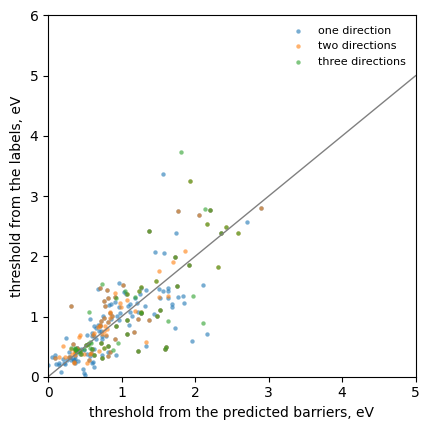

In [10]:
from cmfqsar.hops import saddle_from_barrier, structure_percolation

predicted = {int(i): float(p) for i, p in zip(targets.atom, results["fields, no frame"].predicted)}
for i, h in enumerate(hops.hops):                 # the copies of a hop take its predicted barrier
    if i not in predicted and h.representative in predicted:
        predicted[i] = predicted[h.representative]

labelled, modelled = [], []
for k in range(len(hops.structures)):
    rows = hops.of_structure(k)
    if all(i in predicted for i in rows) and all(np.isfinite(hops.hops[i].saddle) for i in rows):
        labelled.append(structure_percolation(hops, k))
        modelled.append(structure_percolation(hops, k, saddle_from_barrier(hops, predicted)))
print(len(labelled), "structures have a label and a prediction for every one of their hops")
print()
print("%-22s %12s %14s %32s" % ("the network runs in", "structures", "correlation", "mean absolute difference, eV"))
fig, ax = plt.subplots(figsize=(4.4, 4.4))
for direction, label, colour in (("E_1D", "one direction", "tab:blue"), ("E_2D", "two directions", "tab:orange"), ("E_3D", "three directions", "tab:green")):
    a = np.array([row[direction] for row in labelled]); b = np.array([row[direction] for row in modelled])
    both = np.isfinite(a) & np.isfinite(b)
    print("%-22s %12d %+14.2f %32.2f" % (label, both.sum(), np.corrcoef(a[both], b[both])[0, 1], np.mean(np.abs(a[both] - b[both]))))
    ax.scatter(b[both], a[both], s=10, color=colour, alpha=0.6, lw=0, label=label)
ax.plot([0, 5], [0, 5], color="0.5", lw=1); ax.set_xlim(0, 5); ax.set_ylim(0, 6)
ax.set_xlabel("threshold from the predicted barriers, eV"); ax.set_ylabel("threshold from the labels, eV")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

The thresholds from the predicted barriers follow those from the labels, with a mean difference
of about 0.35 eV. That is about the error of the model on one hop, as it should be: a threshold
is the barrier of one hop of the network, the one that closes the path. So the step from a
model of hops to a number for a material holds.

For a screening this is still coarse. Good conductors and poor ones differ by a few tenths of
an eV, which is the size of this error.

## What this notebook does not show

- **The label is a model.** The bond-valence barrier is fast and approximate. Section *The hop
  model on DFT barriers* of the manual repeats the measurement on barriers from density
  functional theory.
- **The model does not carry its scale to another chemistry.** The manual applies it to three
  phosphates and borates, which are electrolytes and not oxides of a transition metal. The
  correlation with their barriers is +0.68 and the q² is below zero: the order is partly right
  and the values are not.
- **Disorder.** Many real conductors have lithium sites that are only partly occupied. The
  program reads such structures with their occupancies; the manual has the section.

## What to take from this notebook

- A crystal is modelled through a local sample, here a hop, with an environment cut out of the
  repeating cell. From there the fields, the kernels and the co-field are those of a molecule.
- Hold out whole structures. Hops of one crystal are related.
- Compare with the counts of atoms. Here they hold half of the variance, and the fields hold
  two thirds.
- A frame is worth something where there is one centre and the environment is wide, as in the
  catalyst series. Around a path with a narrow environment it added nothing.
- A co-field of such a model is a profile along the path. It is read where it stands two
  standard deviations above zero.
- Barriers of hops become a property of a material through the percolation step.

From the command line, `cmf hops structure.cif --bvse --out hops.csv` lists the hops of a
structure with their bond-valence barriers; it needs the package `bvlain` for the labels.

Where to read further in the manual: *A migration path as the sample: the barrier of a Li hop*
has the equations of the kernel in the frame of a hop, the full tables and the three hosts, and
the sections after it treat partly occupied sites and barriers from density functional theory.